<a href="https://colab.research.google.com/github/mariaalshuttary14-ai/MyLabN/blob/main/spectral_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install numpy matplotlib scikit-learn scikit-image

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.cluster import SpectralClustering
from sklearn.cluster import spectral_clustering

from sklearn.feature_extraction import image as sk_image
from skimage import data
from skimage.transform import rescale
from skimage.filters import gaussian

In [ ]:
X, y = make_circles(
    n_samples=1000,
    factor=0.5,
    noise=0.05,
    random_state=42
)

print("Dataset shape:", X.shape)

Dataset shape: (1000, 2)


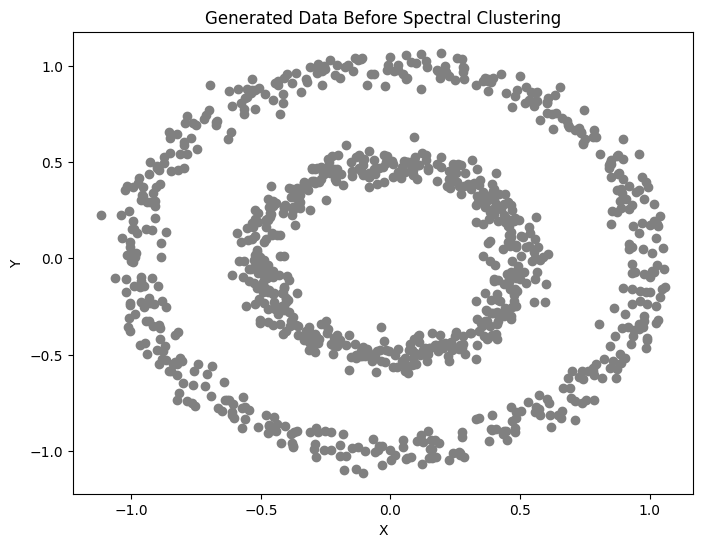

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(X[:, 0], X[:, 1], color="gray")

plt.title("Generated Data Before Spectral Clustering")
plt.xlabel("X")
plt.ylabel("Y")

plt.savefig("spectral_data_before.png")
plt.show()

In [ ]:
spectral_model = SpectralClustering(
    n_clusters=2,
    affinity="nearest_neighbors",
    random_state=42
)

labels = spectral_model.fit_predict(X)

print("Clustering completed!")
print("Number of labels:", len(labels))
print("Clusters found:", np.unique(labels))

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Clustering completed!
Number of labels: 1000
Clusters found: [0 1]


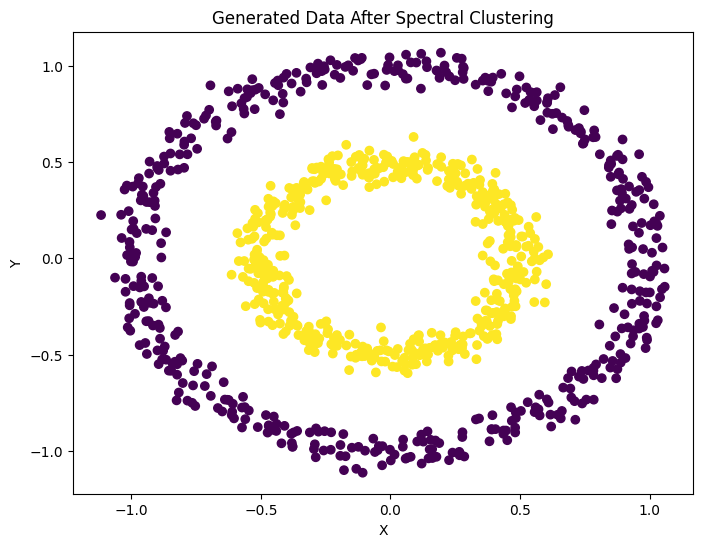

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    cmap="viridis"
)

plt.title("Generated Data After Spectral Clustering")
plt.xlabel("X")
plt.ylabel("Y")

plt.savefig("spectral_data_after.png")
plt.show()

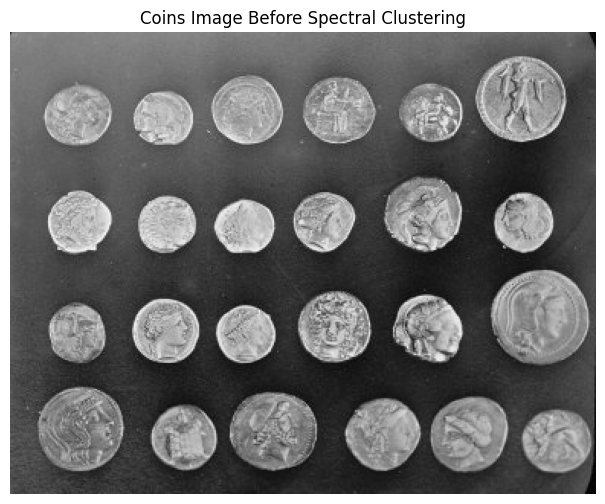

In [ ]:
from skimage import data
import matplotlib.pyplot as plt

coins = data.coins()

plt.figure(figsize=(10, 6))
plt.imshow(coins, cmap="gray")
plt.title("Coins Image Before Spectral Clustering")
plt.axis("off")

plt.savefig("spectral_image_before.png")
plt.show()

Original image shape: (303, 384)
Smaller image shape: (61, 77)


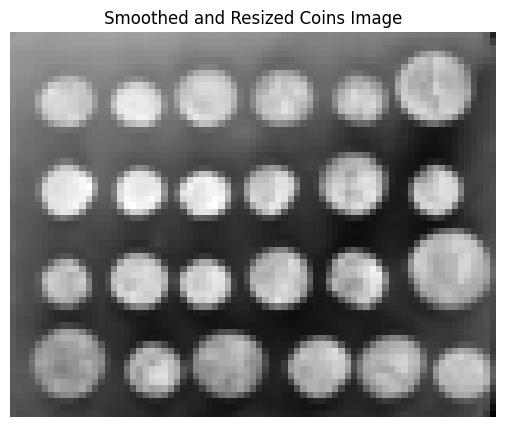

In [ ]:
from skimage.filters import gaussian
from skimage.transform import rescale
import matplotlib.pyplot as plt

smooth_coins = gaussian(coins, sigma=2)

small_coins = rescale(
    smooth_coins,
    0.2,
    anti_aliasing=True
)

print("Original image shape:", coins.shape)
print("Smaller image shape:", small_coins.shape)

plt.figure(figsize=(8, 5))
plt.imshow(small_coins, cmap="gray")
plt.title("Smoothed and Resized Coins Image")
plt.axis("off")
plt.show()

In [ ]:
import numpy as np
from sklearn.feature_extraction import image as sk_image
from sklearn.cluster import spectral_clustering

graph = sk_image.img_to_graph(small_coins)

graph.data = np.exp(
    -10 * graph.data / graph.data.std()
)

labels = spectral_clustering(
    graph,
    n_clusters=25,
    assign_labels="discretize",
    random_state=42
)

labels = labels.reshape(small_coins.shape)

print("Image clustering completed!")
print("Label image shape:", labels.shape)
print("Number of clusters found:", len(np.unique(labels)))

Image clustering completed!
Label image shape: (61, 77)
Number of clusters found: 25


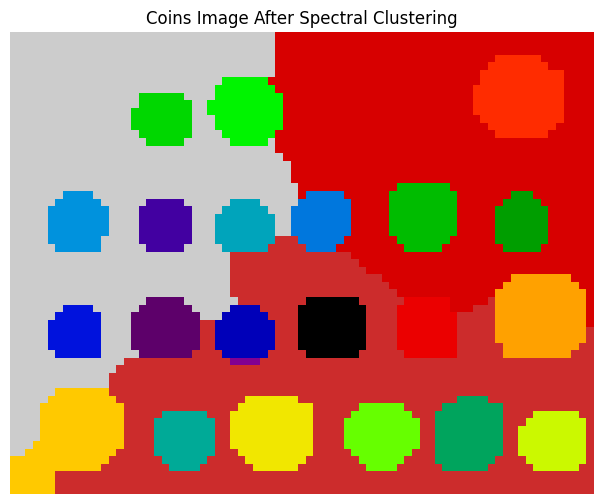

In [ ]:
plt.figure(figsize=(10, 6))

plt.imshow(labels, cmap="nipy_spectral")
plt.title("Coins Image After Spectral Clustering")
plt.axis("off")

plt.savefig("spectral_image_after.png")
plt.show()